In [1]:
import fasttext
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math
import numpy as np

In [2]:
# functions
def cossim(vec1, vec2):
    """Return cosine similarity between vec1 and vec2"""
    dot_product = sum(a*b for a, b in zip(vec1, vec2))
    magnitude1 = math.sqrt(sum([val**2 for val in vec1]))
    magnitude2 = math.sqrt(sum([val**2 for val in vec2]))
    return dot_product / (magnitude1 * magnitude2)
def euclid(vec1, vec2):
    vec1, vec2 = np.array(vec1), np.array(vec2)
    return np.linalg.norm(vec1 - vec2)
def get(model, word):
    """Return word embedding for word as in model"""
    return model.get_word_vector(word)

In [3]:
# word embedding models load
en_model_path = 'cc.en.300.bin'
es_model_path = 'cc.es.300.bin'
de_model_path = 'cc.de.300.bin'

In [4]:
en = fasttext.load_model(en_model_path)
es = fasttext.load_model(es_model_path)
de = fasttext.load_model(de_model_path)

In [5]:
# target group: gender names
genders = {
    "en":[
        # ['male', 'he', 'him', 'his', 'man', 'boy', 'son', 'brother'], 
        # ['female', 'she', 'her', 'hers', 'woman', 'girl', 'daughter', 'sister'], 
        # ['nonbinary', 'they', 'them', 'theirs', 'person', 'child', 'children', 'sibling']
        ['man'],
        ['woman'],
        # ['person']
        ],
    "es":[
        # ['masculino', 'él', 'hombre', 'chico', 'hijo', 'hermano'], 
        # ['feminino', 'ella', 'mujer', 'chica', 'hija', 'hermana'], 
        # ['persona', 'individual'],
        ['hombre'],
        ['mujer'],
        # ['persona']
        ],
    "de":[
        # ['er', 'ihm', 'sein', 'Mann', 'Junge', 'Sohn', 'Bruder'],
        # ['sie', 'ihr', 'Frau', 'Mädchen', 'Tochter', 'Schwester'],
        # ['nichtbinär', 'ihres', 'Person', 'Kind', 'Kinder', 'Geschwister'],
        ['Mann'],
        ['Frau'],
        # ['Individuum']
        ],
}

# target group: determiners (gendered or ungendered definite articles)
determiners = {
    "en":[['the']],
    "es":[['el', 'la']],
    "de":[['der', 'die', 'das']]
}


In [37]:
bar = '---------------------------------------------------------------'

In [6]:

# CONTROL DATA dataframe initialization
control_data = pd.DataFrame(columns=["LANGUAGE", "TARGET CATEGORY", "TARGET WORD", "REFERENCE PART OF SPEECH", 
                                     "REFERENCE ASSOCIATION/GRAMMATICAL GENDER", "REFERENCE TRANSLATION", 
                                     "REFERENCE WORD", "COSINE SIMILARITY"])

# TEST DATA dataframe initialization
test_data = pd.DataFrame(columns=["LANGUAGE", "NOUN GRAMMATICAL GENDER", "NOUN TRANSLATION", "NOUN", 
                                  "ADJECTIVE ASSOCIATION", "ADJECTIVE TRANSLATION", "ADJECTIVE", "COSINE SIMILARITY"])


In [7]:

# giving variables string names for writing to csv
models = {"en": en, "es": es, "de": de}
target_types = {"genders": genders, "determiners": determiners}



In [42]:
# Corrected dataframe loading and checking
df = pd.read_csv('RAW_DATA.csv', sep=',')
for lang in languages:
    noun_df = df[(df['LANGUAGE'] == lang) & (df['PART OF SPEECH'] == 'noun')]
    adj_df = df[(df['LANGUAGE'] == lang) & (df['PART OF SPEECH'] == 'adjective')]
    print(f"{lang} nouns: {len(noun_df)}")
    print(f"{lang} adjectives: {len(adj_df)}")


en nouns: 86
en adjectives: 400
es nouns: 80
es adjectives: 400
de nouns: 76
de adjectives: 400


In [43]:
# calculation type - cossim (cosine similarity) or euclid (euclidian distance)
calc = cossim

In [44]:
# collection of data (writing to csv for CONTROL DATA and TEST DATA)
for lang in models.keys():
    print(bar*2)
    print(f'processing: {lang}')
    for target_category, target_lists in target_types.items():
        print(f'processing: {target_category}')
        for sublist_index, target_list in enumerate(target_lists[lang]):
            print(f'processing: {target_list}')
            for pos in ['noun', 'adjective']:
                for target_word in target_list:
                    print(f'processing: {target_word}')
                    for assoc_gender in ['masculine', 'feminine', 'neuter']:
                        print(f'processing: {assoc_gender}')
                        temp_df = df[(df['LANGUAGE'] == lang) & 
                                    (df['PART OF SPEECH'] == pos) & 
                                    (df['ASSOCIATION/GRAMMATICAL GENDER'] == assoc_gender)]
                        
                        for _, ref_row in temp_df.iterrows():
                            ref_vec = get(models[lang], ref_row['WORD'])
                            target_vec = get(models[lang], target_word)
                            similarity = calc(ref_vec, target_vec)
                            sublist_name = target_word if target_category == 'determiners' else ["Male attributes", "Female attributes", "Neuter attributes"][sublist_index]
                            control_data = control_data._append({"LANGUAGE": lang, 
                                                                "TARGET CATEGORY": target_category, 
                                                                "TARGET WORD": target_word, 
                                                                "SUB-LIST": sublist_name,
                                                                "REFERENCE PART OF SPEECH": pos, 
                                                                "REFERENCE ASSOCIATION/GRAMMATICAL GENDER": assoc_gender,
                                                                "REFERENCE TRANSLATION": ref_row['TRANSLATION'], 
                                                                "REFERENCE WORD": ref_row['WORD'], 
                                                                "COSINE SIMILARITY": similarity}, ignore_index=True)

    noun_df = df[(df['LANGUAGE'] == lang) & (df['PART OF SPEECH'] == 'noun')]
    adj_df = df[(df['LANGUAGE'] == lang) & (df['PART OF SPEECH'] == 'adjective')]
    print(bar)
    for _, noun_row in noun_df.iterrows():
        print(f'processing: {noun_row}')
        for _, adj_row in adj_df.iterrows():
            print(f'processing: {adj_row}')
            noun_vec = get(models[lang], noun_row['WORD'])
            adj_vec = get(models[lang], adj_row['WORD'])
            similarity = calc(noun_vec, adj_vec)
            test_data = test_data._append({"LANGUAGE": lang, 
                                        "NOUN GRAMMATICAL GENDER": noun_row['ASSOCIATION/GRAMMATICAL GENDER'], 
                                        "NOUN TRANSLATION": noun_row['TRANSLATION'], 
                                        "NOUN": noun_row['WORD'], 
                                        "ADJECTIVE ASSOCIATION": adj_row['ASSOCIATION/GRAMMATICAL GENDER'], 
                                        "ADJECTIVE TRANSLATION": adj_row['TRANSLATION'], 
                                        "ADJECTIVE": adj_row['WORD'], 
                                        "COSINE SIMILARITY": similarity}, ignore_index=True)

------------------------------------------------------------------------------------------------------------------------------
processing: en
processing: genders
processing: ['man']
processing: man
processing: masculine
processing: feminine
processing: neuter
processing: man
processing: masculine
processing: feminine
processing: neuter
processing: ['woman']
processing: woman
processing: masculine
processing: feminine
processing: neuter
processing: woman
processing: masculine
processing: feminine
processing: neuter
processing: determiners
processing: ['the']
processing: the
processing: masculine
processing: feminine
processing: neuter
processing: the
processing: masculine
processing: feminine
processing: neuter
---------------------------------------------------------------
processing: PART OF SPEECH                      noun
LANGUAGE                              en
ASSOCIATION/GRAMMATICAL GENDER    neuter
WORD                               spoon
TRANSLATION                        spoon

processing: PART OF SPEECH                    adjective
LANGUAGE                                 en
ASSOCIATION/GRAMMATICAL GENDER    masculine
WORD                                fittest
TRANSLATION                         fittest
cosine_similarity_to_target        0.314992
Name: 342, dtype: object
processing: PART OF SPEECH                    adjective
LANGUAGE                                 en
ASSOCIATION/GRAMMATICAL GENDER    masculine
WORD                                   poor
TRANSLATION                            poor
cosine_similarity_to_target        0.314694
Name: 343, dtype: object
processing: PART OF SPEECH                     adjective
LANGUAGE                                  en
ASSOCIATION/GRAMMATICAL GENDER     masculine
WORD                              invincible
TRANSLATION                       invincible
cosine_similarity_to_target          0.31275
Name: 344, dtype: object
processing: PART OF SPEECH                    adjective
LANGUAGE                           

processing: PART OF SPEECH                    adjective
LANGUAGE                                 en
ASSOCIATION/GRAMMATICAL GENDER     feminine
WORD                              unmarried
TRANSLATION                       unmarried
cosine_similarity_to_target        0.511415
Name: 443, dtype: object
processing: PART OF SPEECH                    adjective
LANGUAGE                                 en
ASSOCIATION/GRAMMATICAL GENDER     feminine
WORD                                  young
TRANSLATION                           young
cosine_similarity_to_target        0.504642
Name: 444, dtype: object
processing: PART OF SPEECH                    adjective
LANGUAGE                                 en
ASSOCIATION/GRAMMATICAL GENDER     feminine
WORD                                elderly
TRANSLATION                         elderly
cosine_similarity_to_target        0.456597
Name: 445, dtype: object
processing: PART OF SPEECH                    adjective
LANGUAGE                                 

processing: PART OF SPEECH                    adjective
LANGUAGE                                 en
ASSOCIATION/GRAMMATICAL GENDER     feminine
WORD                              corpulent
TRANSLATION                       corpulent
cosine_similarity_to_target        0.299523
Name: 546, dtype: object
processing: PART OF SPEECH                     adjective
LANGUAGE                                  en
ASSOCIATION/GRAMMATICAL GENDER      feminine
WORD                              lascivious
TRANSLATION                       lascivious
cosine_similarity_to_target         0.298449
Name: 547, dtype: object
processing: PART OF SPEECH                    adjective
LANGUAGE                                 en
ASSOCIATION/GRAMMATICAL GENDER     feminine
WORD                              surrogate
TRANSLATION                       surrogate
cosine_similarity_to_target        0.297624
Name: 548, dtype: object
processing: PART OF SPEECH                      adjective
LANGUAGE                         

processing: PART OF SPEECH                    adjective
LANGUAGE                                 en
ASSOCIATION/GRAMMATICAL GENDER    masculine
WORD                                  hunky
TRANSLATION                           hunky
cosine_similarity_to_target        0.419548
Name: 247, dtype: object
processing: PART OF SPEECH                     adjective
LANGUAGE                                  en
ASSOCIATION/GRAMMATICAL GENDER     masculine
WORD                              paraplegic
TRANSLATION                       paraplegic
cosine_similarity_to_target         0.412933
Name: 248, dtype: object
processing: PART OF SPEECH                     adjective
LANGUAGE                                  en
ASSOCIATION/GRAMMATICAL GENDER     masculine
WORD                              chivalrous
TRANSLATION                       chivalrous
cosine_similarity_to_target         0.409298
Name: 249, dtype: object
processing: PART OF SPEECH                    adjective
LANGUAGE                     

processing: PART OF SPEECH                       adjective
LANGUAGE                                    en
ASSOCIATION/GRAMMATICAL GENDER       masculine
WORD                              contemptible
TRANSLATION                       contemptible
cosine_similarity_to_target           0.311604
Name: 347, dtype: object
processing: PART OF SPEECH                    adjective
LANGUAGE                                 en
ASSOCIATION/GRAMMATICAL GENDER    masculine
WORD                              garrulous
TRANSLATION                       garrulous
cosine_similarity_to_target        0.311568
Name: 348, dtype: object
processing: PART OF SPEECH                     adjective
LANGUAGE                                  en
ASSOCIATION/GRAMMATICAL GENDER     masculine
WORD                              illiterate
TRANSLATION                       illiterate
cosine_similarity_to_target         0.311554
Name: 349, dtype: object
processing: PART OF SPEECH                    adjective
LANGUAGE         

... (1,588 outputs left out)

processing: PART OF SPEECH                       adjective
LANGUAGE                                    de
ASSOCIATION/GRAMMATICAL GENDER        feminine
WORD                              fürsorgliche
TRANSLATION                             caring
cosine_similarity_to_target           0.355915
Name: 1324, dtype: object
processing: PART OF SPEECH                       adjective
LANGUAGE                                    de
ASSOCIATION/GRAMMATICAL GENDER        feminine
WORD                              schnippische
TRANSLATION                             snippy
cosine_similarity_to_target           0.355116
Name: 1325, dtype: object
processing: PART OF SPEECH                                   adjective
LANGUAGE                                                de
ASSOCIATION/GRAMMATICAL GENDER                    feminine
WORD                                        emanzipierende
TRANSLATION                       in the middle of nowhere
cosine_similarity_to_target                       0.3

processing: PART OF SPEECH                    adjective
LANGUAGE                                 de
ASSOCIATION/GRAMMATICAL GENDER     feminine
WORD                              unwirsche
TRANSLATION                           surly
cosine_similarity_to_target        0.325917
Name: 1363, dtype: object
processing: PART OF SPEECH                     adjective
LANGUAGE                                  de
ASSOCIATION/GRAMMATICAL GENDER      feminine
WORD                                 erbende
TRANSLATION                       inheriting
cosine_similarity_to_target         0.325117
Name: 1364, dtype: object
processing: PART OF SPEECH                           adjective
LANGUAGE                                        de
ASSOCIATION/GRAMMATICAL GENDER            feminine
WORD                              alleinregierende
TRANSLATION                         sole governing
cosine_similarity_to_target               0.325057
Name: 1365, dtype: object
processing: PART OF SPEECH                    

processing: PART OF SPEECH                    adjective
LANGUAGE                                 de
ASSOCIATION/GRAMMATICAL GENDER     feminine
WORD                              abgängige
TRANSLATION                         missing
cosine_similarity_to_target        0.305435
Name: 1400, dtype: object
processing: PART OF SPEECH                       adjective
LANGUAGE                                    de
ASSOCIATION/GRAMMATICAL GENDER        feminine
WORD                              eigensinnige
TRANSLATION                        opinionated
cosine_similarity_to_target           0.304936
Name: 1401, dtype: object
processing: PART OF SPEECH                            adjective
LANGUAGE                                         de
ASSOCIATION/GRAMMATICAL GENDER             feminine
WORD                               schwerverletzter
TRANSLATION                       seriously injured
cosine_similarity_to_target                 0.30464
Name: 1402, dtype: object
processing: PART OF SPEECH  

processing: PART OF SPEECH                               adjective
LANGUAGE                                            de
ASSOCIATION/GRAMMATICAL GENDER                feminine
WORD                              intergeschlechtliche
TRANSLATION                                   intersex
cosine_similarity_to_target                   0.274432
Name: 1439, dtype: object
processing: PART OF SPEECH                      adjective
LANGUAGE                                   de
ASSOCIATION/GRAMMATICAL GENDER       feminine
WORD                              aufgelesene
TRANSLATION                         picked up
cosine_similarity_to_target          0.273781
Name: 1440, dtype: object
processing: PART OF SPEECH                        adjective
LANGUAGE                                     de
ASSOCIATION/GRAMMATICAL GENDER         feminine
WORD                              reputierliche
TRANSLATION                          reputierli
cosine_similarity_to_target             0.27326
Name: 1441, dtype:

In [46]:
# convert dataframes to csv
control_data.to_csv('CONTROL DATA.csv', index=False)
test_data.to_csv('TEST DATA.csv', index=False)

In [47]:


# plot from csv to boxplots - CONTROL DATA
for lang in models.keys():
    plt.figure(figsize=(40, 34))

    temp_data = control_data[control_data['LANGUAGE'] == lang]
    
    fig, axs = plt.subplots(2, 2)

    for ax, (target_word, pos) in zip(axs.flat, [('genders', 'noun'), ('genders', 'adjective'), ('determiners', 'noun'), ('determiners', 'adjective')]):
        subset = temp_data[(temp_data['TARGET CATEGORY'] == target_word) & (temp_data['REFERENCE PART OF SPEECH'] == pos)]
        
        # Create a boxplot
        sns.boxplot(ax=ax, x='REFERENCE ASSOCIATION/GRAMMATICAL GENDER', y='COSINE SIMILARITY', hue='SUB-LIST', data=subset)
        ax.set_title(f"{target_word.capitalize()} - {pos.capitalize()}")
        ax.legend(loc='upper right')

    plt.tight_layout()
    plt.savefig(f"Control_Data_{lang}.png")
    plt.subplots_adjust(hspace=0.3, wspace=0.3)
    plt.close()

# plot from csv to boxplots - TEST DATA
for lang in models.keys():
    plt.figure(figsize=(14, 10))

    temp_data = test_data[test_data['LANGUAGE'] == lang]
    
    sns.boxplot(x='NOUN GRAMMATICAL GENDER', y='COSINE SIMILARITY', hue='ADJECTIVE ASSOCIATION', data=temp_data)
    
    plt.title(f"Test Data - {lang}")
    plt.savefig(f"Test_Data_{lang}.png")
    plt.close()




<Figure size 4000x3400 with 0 Axes>

<Figure size 4000x3400 with 0 Axes>

<Figure size 4000x3400 with 0 Axes>

In [48]:
print(models.keys())

dict_keys(['en', 'es', 'de'])


In [49]:
print("Data check:")
for lang in models.keys():
    print(f"Number of entries for {lang}: {len(df[df['LANGUAGE'] == lang])}")

print("\nPart of speech distribution:")
for lang in models.keys():
    for pos in ['noun', 'adjective']:
        print(f"Number of {pos}s in {lang}: {len(df[(df['LANGUAGE'] == lang) & (df['PART OF SPEECH'] == pos)])}")

print("\nAssociation/Grammatical gender distribution:")
for lang in models.keys():
    for assoc_gender in ['masculine', 'feminine', 'neuter']:
        print(f"Number of {assoc_gender} words in {lang}: {len(df[(df['LANGUAGE'] == lang) & (df['ASSOCIATION/GRAMMATICAL GENDER'] == assoc_gender)])}")


Data check:
Number of entries for en: 486
Number of entries for es: 480
Number of entries for de: 476

Part of speech distribution:
Number of nouns in en: 86
Number of adjectives in en: 400
Number of nouns in es: 80
Number of adjectives in es: 400
Number of nouns in de: 76
Number of adjectives in de: 400

Association/Grammatical gender distribution:
Number of masculine words in en: 200
Number of feminine words in en: 200
Number of neuter words in en: 86
Number of masculine words in es: 235
Number of feminine words in es: 245
Number of neuter words in es: 0
Number of masculine words in de: 242
Number of feminine words in de: 234
Number of neuter words in de: 0


In [53]:
import progressbar

In [51]:
!pip install progressbar

  Preparing metadata (setup.py) ... done
  Created wheel for progressbar: filename=progressbar-2.5-py3-none-any.whl size=12067 sha256=3fb024c1609fcee9c445afd65fed63aa242d65aa9c2e65e0a521f47593bb318b
  Stored in directory: /Users/georgeflint/Library/Caches/pip/wheels/8d/bb/b2/5353b966ac6f3c5e1000629a9a5f6aed41794487f551e32efc
Successfully built progressbar


Average similarity for the same gender: 0.16098737853751297
Average similarity for different genders: 0.10022907933232678
T-test statistic: 143.0339858316671, p-value: 0.0
                            OLS Regression Results                            
Dep. Variable:      COSINE SIMILARITY   R-squared:                       0.135
Model:                            OLS   Adj. R-squared:                  0.135
Method:                 Least Squares   F-statistic:                 2.046e+04
Date:                Fri, 28 Jul 2023   Prob (F-statistic):               0.00
Time:                        12:08:16   Log-Likelihood:             1.7144e+05
No. Observations:              131200   AIC:                        -3.429e+05
Df Residuals:                  131198   BIC:                        -3.429e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err     

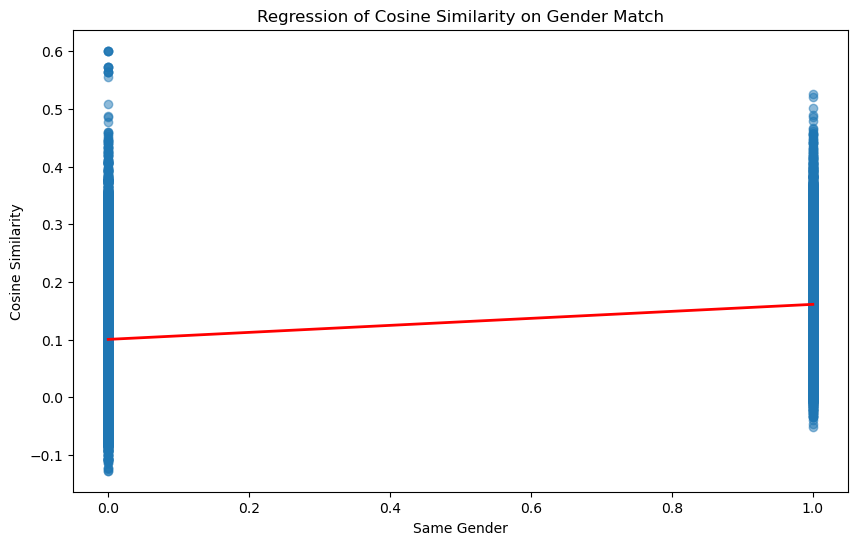

In [54]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

# Assuming that test_data DataFrame is already defined and populated
test_data['SAME_GENDER'] = test_data['NOUN GRAMMATICAL GENDER'] == test_data['ADJECTIVE ASSOCIATION']

# Calculate average similarity for the same and different gender groups
avg_same_gender = test_data[test_data['SAME_GENDER'] == True]['COSINE SIMILARITY'].mean()
avg_diff_gender = test_data[test_data['SAME_GENDER'] == False]['COSINE SIMILARITY'].mean()

print(f'Average similarity for the same gender: {avg_same_gender}')
print(f'Average similarity for different genders: {avg_diff_gender}')

# Run an independent samples t-test
t_stat, p_val = ttest_ind(test_data[test_data['SAME_GENDER'] == True]['COSINE SIMILARITY'],
                          test_data[test_data['SAME_GENDER'] == False]['COSINE SIMILARITY'])

print(f'T-test statistic: {t_stat}, p-value: {p_val}')

# Fit a regression model
X = sm.add_constant(test_data['SAME_GENDER'].astype(int))  # add an intercept (beta_0) to our model
y = test_data['COSINE SIMILARITY']

model = sm.OLS(y, X)
results = model.fit()

print(results.summary())

# Plotting
plt.figure(figsize=(10,6))
plt.scatter(test_data['SAME_GENDER'], test_data['COSINE SIMILARITY'], alpha=0.5)
plt.plot(test_data['SAME_GENDER'], results.predict(X), color='red', linewidth=2)
plt.xlabel('Same Gender')
plt.ylabel('Cosine Similarity')
plt.title('Regression of Cosine Similarity on Gender Match')
plt.show()
